In [24]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [25]:
df = pd.read_csv('water_potability.csv')

In [26]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [27]:
print("--- DATASET INFORMATION ---")
df.info()

--- DATASET INFORMATION ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [28]:
print("--- STATISTICAL SUMMARY ---")
display(df.describe())

--- STATISTICAL SUMMARY ---


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [29]:
print("--- MISSING VALUES ---")
print(df.isnull().sum())

--- MISSING VALUES ---
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


In [30]:
missing_cols = ['ph', 'Sulfate', 'Trihalomethanes']

for col in missing_cols:
    df[col] = df[col].fillna(df.groupby('Potability')[col].transform('mean'))

print(df.isnull().sum())

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


--- CLASS DISTRIBUTION (%) ---
Potability
0    60.99
1    39.01
Name: proportion, dtype: float64


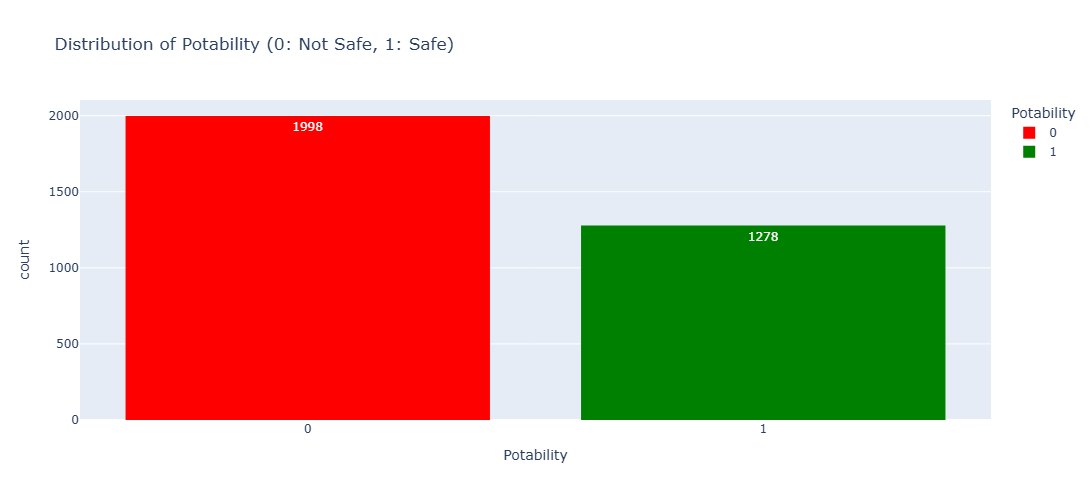

In [31]:
target_counts = df['Potability'].value_counts(normalize=True) * 100
print("--- CLASS DISTRIBUTION (%) ---")
print(target_counts.round(2))

fig_target = px.histogram(
    df, x='Potability', color='Potability',
    title='Distribution of Potability (0: Not Safe, 1: Safe)',
    color_discrete_map={0: 'red', 1: 'green'},
    text_auto=True,
    width=800, height=500)
fig_target.update_layout(xaxis_type='category')
fig_target.show()

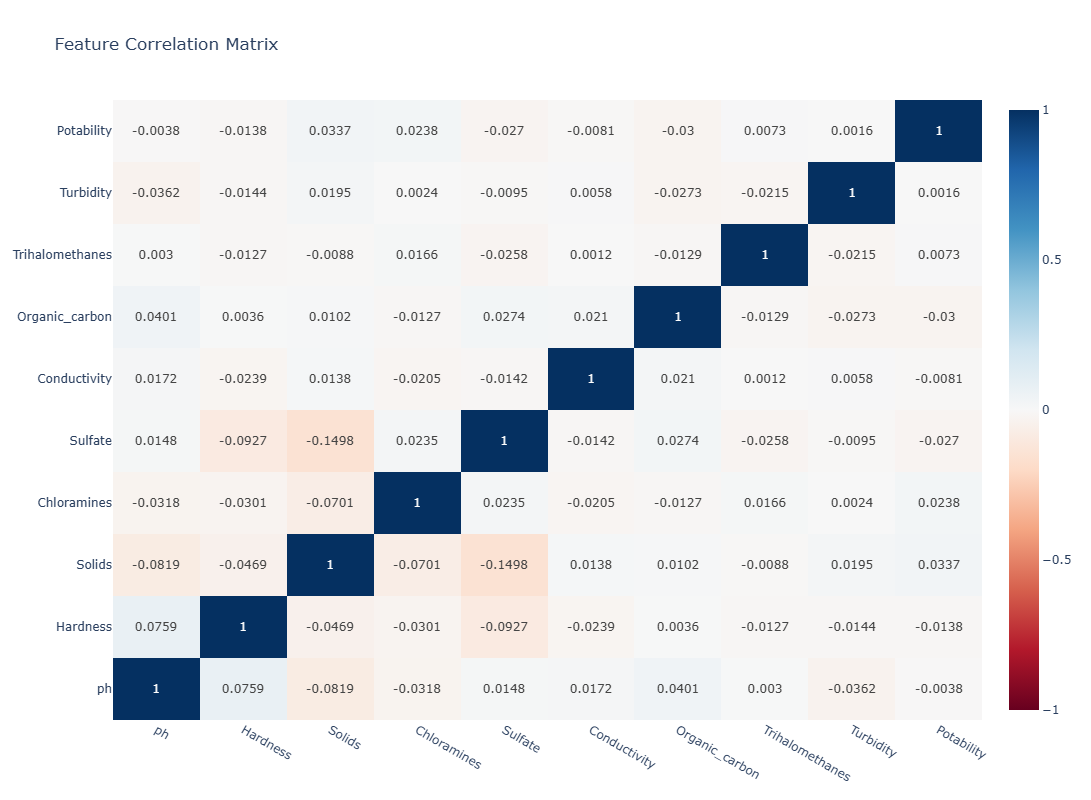

--- CORRELATIONS WITH POTABILITY ---
Potability         1.000000
Solids             0.033743
Chloramines        0.023779
Trihalomethanes    0.007305
Turbidity          0.001581
ph                -0.003848
Conductivity      -0.008128
Hardness          -0.013837
Sulfate           -0.026957
Organic_carbon    -0.030001
Name: Potability, dtype: float64


In [35]:
corr_matrix = df.corr()

fig_corr = go.Figure(data=go.Heatmap(
    z=corr_matrix.values, x=corr_matrix.columns, y=corr_matrix.index,
    colorscale='RdBu', zmin=-1, zmax=1,
    text=corr_matrix.round(4).values, texttemplate="%{text}"))
fig_corr.update_layout(
    title='Feature Correlation Matrix', 
    width=900, height=800)
fig_corr.show()

print("--- CORRELATIONS WITH POTABILITY ---")
print(corr_matrix['Potability'].sort_values(ascending=False))

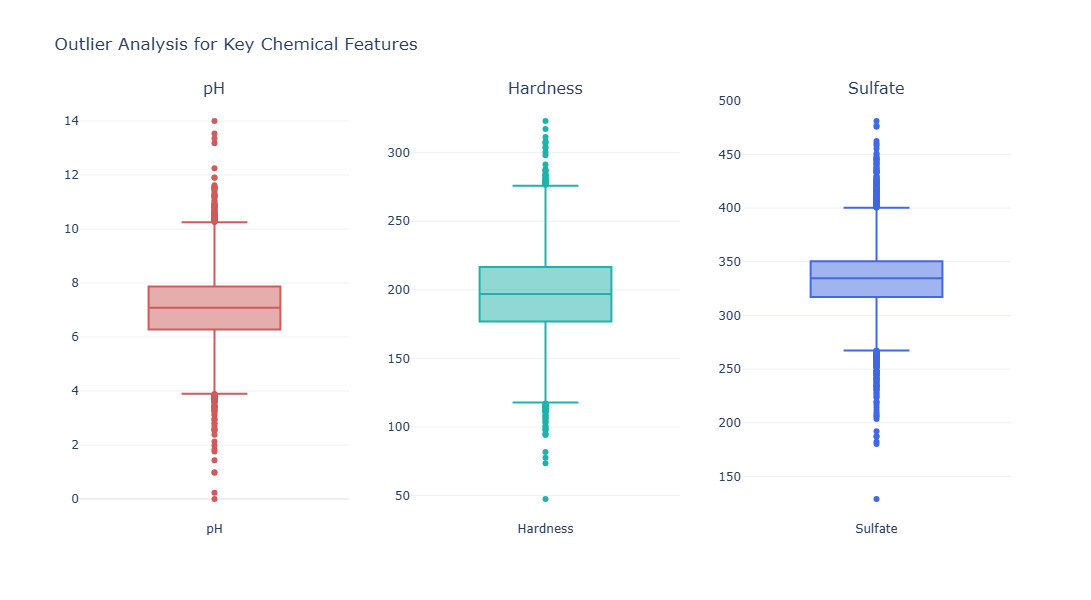

In [33]:
fig_box = make_subplots(rows=1, cols=3, subplot_titles=("pH", "Hardness", "Sulfate"))

fig_box.add_trace(go.Box(y=df['ph'], name='pH', boxpoints='outliers', marker_color='indianred'), row=1, col=1)
fig_box.add_trace(go.Box(y=df['Hardness'], name='Hardness', boxpoints='outliers', marker_color='lightseagreen'), row=1, col=2)
fig_box.add_trace(go.Box(y=df['Sulfate'], name='Sulfate', boxpoints='outliers', marker_color='royalblue'), row=1, col=3)

fig_box.update_layout(
    title_text="Outlier Analysis for Key Chemical Features", 
    width=1000, height=600, 
    showlegend=False, template="plotly_white")
fig_box.show()

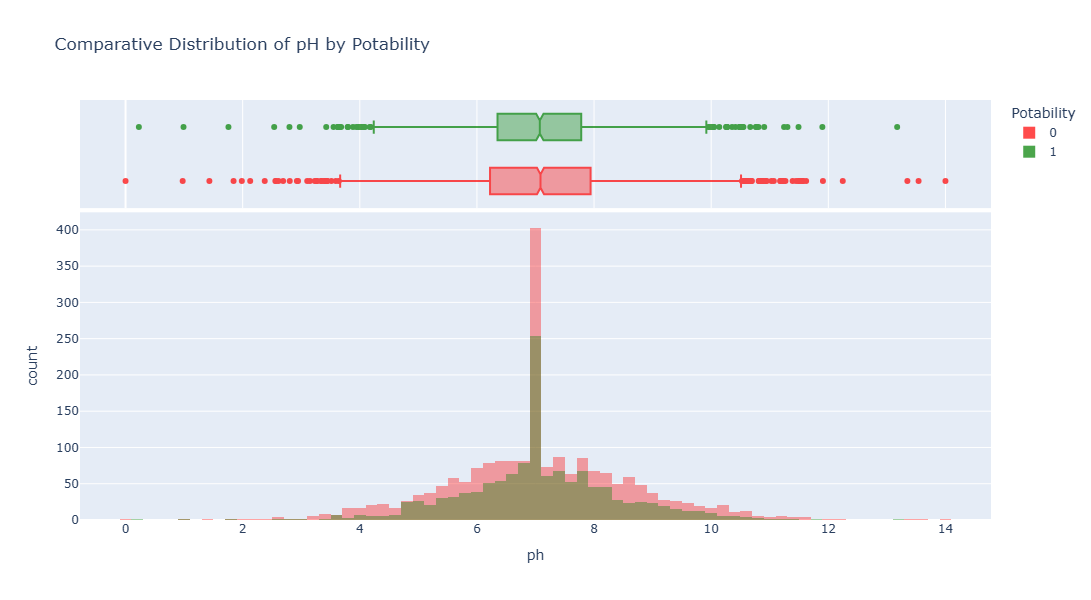

In [34]:
fig_hist = px.histogram(
    df, x="ph", color="Potability", marginal="box", 
    barmode="overlay", 
    title="Comparative Distribution of pH by Potability",
    color_discrete_map={0: 'red', 1: 'green'},
    width=900, height=600)
fig_hist.update_traces(opacity=0.7)
fig_hist.show()